# Early-Career Potential Model: walkthrough

**Client:** NBA franchise front office (Deloitte case study) · **Prepared by:** Changa Fernando (S3842381) · ISYS3419 Assessment 3

This notebook walks through the artefact in the order it was built: data, outcome definition, features, model
choice, evaluation, explanation, live scoring and monitoring. The heavy steps (model selection and the
2,000-resample backtest) are run by `python run_pipeline.py all`. Here they are loaded from `outputs/`, so the
notebook runs in under a minute. Set `RECOMPUTE = True` to recompute them in the notebook (about 3 minutes).

In [1]:
import os, json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
from ecp.config import load_config
from ecp import pipeline as pl
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
RECOMPUTE = False
cfg = load_config()
D = pl.prepare(cfg)          # player-seasons, cohort, outcome labels and features for h = 1, 2, 3
coh = D["coh"]
print(f"Player-seasons: {len(D['ps']):,} | cohort (debuts 1996+): {len(coh):,} | labelled (debut <= 2018): {int(coh.labelled.sum()):,}")

Player-seasons: 16,949 | cohort (debuts 1996+): 2,448 | labelled (debut <= 2018): 1,718


## 1. Data quality: what the ingest step found

The ingest step (`ecp/ingest.py`) runs next to the raw files and writes an audit report. Four defects mattered.
The most consequential is that the **games-started flag changes meaning** over time. The Assessment 2 prototype
used it as a feature.

In [2]:
rep = json.loads((cfg["paths"]["processed_dir"] / "ingest_report.json").read_text())
print(json.dumps(rep["data_quality"], indent=1))
ps = D["ps"]
starts = (ps.groupby("season").started.sum() / ps.groupby("season").gp.sum()).round(2)
pd.DataFrame({"share of appearances flagged 'started'": starts}).T.loc[:, [1995, 1996, 2000, 2010, 2016, 2017, 2020, 2021, 2025]]

{
 "rows_read": 1669922,
 "regular_season_rows": 1504443,
 "cup_final_rows_excluded": 90,
 "rows_before_first_season": 485431,
 "rows_missing_minutes": 146318,
 "rows_missing_minutes_with_points": 0,
 "rows_team_id_restored": 45935,
 "rows_team_id_unresolved": 0
}


season,1995,1996,2000,2010,2016,2017,2020,2021,2025
share of appearances flagged 'started',0.0,0.87,0.44,0.92,0.9,0.48,0.47,0.0,0.46


About 90% of appearances in 1996–2016 are flagged as starts, against about 47% from 2017, which is the plausible value
(5 starters out of about 10–11 players used). A model trained on the older seasons would read every current
player as a bench player, so the field is excluded and watched by a monitoring check.

## 2. What counts as success: two outcome constructs

* **Volume (A2 prototype):** a season in the league's top 20% by total Game Score.
* **Rate (recommended):** a rotation season (1,000+ minutes, scaled for short seasons) in the top third of rotation players by Game Score **per 100 possessions**.

Either way, a *contributor* has at least two such seasons in career years 4–8, and players who leave the league count as non-contributors.

In [3]:
lab = coh[coh.labelled]
print("Base rate  volume: {:.1%}   rate: {:.1%}".format(lab.y_volume.mean(), lab.y_rate.mean()))
display(pd.crosstab(lab.y_volume.map({0:'not volume',1:'volume contributor'}), lab.y_rate.map({0:'not rate',1:'rate contributor'})))
print("Volume only (minutes without per-possession impact):", ", ".join(lab[(lab.y_volume==1)&(lab.y_rate==0)].sort_values('debut').name.tail(6)))
print("Rate only (efficient in a smaller role):            ", ", ".join(lab[(lab.y_volume==0)&(lab.y_rate==1)].sort_values('debut').name.tail(6)))

Base rate  volume: 16.6%   rate: 14.5%


y_rate,not rate,rate contributor
y_volume,,
not volume,1401,32
volume contributor,68,217


Volume only (minutes without per-possession impact): Derrick White, Josh Hart, Mikal Bridges, Donte DiVincenzo, Anfernee Simons, Gary Trent Jr.
Rate only (efficient in a smaller role):             Nerlens Noel, Richaun Holmes, Norman Powell, Marvin Bagley III, Mitchell Robinson, Moritz Wagner


The two definitions agree on 217 players. The disagreements show what each one rewards. The volume-only
group includes defensive wings such as Mikal Bridges and OG Anunoby. That is a known limit of box-score
Game Score, which under-credits defence, and it is recorded in the model card.

## 3. Features: what the front office knows after one, two or three seasons

In [4]:
X3 = D["X"][3]
pid = coh.index[coh.name == "Jalen Brunson"][0]
cols = ["games", "mpg", "gmsc_100", "pts_100", "ast_100", "ts_vs_league", "best_rate_pct", "last_gmsc_pct", "age_debut", "draft_pick"]
display(pd.DataFrame({f"after {h} season(s)": D["X"][h].loc[pid, cols] for h in (1, 2, 3)}).round(3))
print(f"{X3.shape[1]} features at h = 3. Production is per 100 possessions relative to the league in the same seasons.")

,after 1 season(s),after 2 season(s),after 3 season(s)
games,73.000,129.000,197.000
mpg,21.274,19.791,21.401
gmsc_100,-2.134,-1.208,0.160
pts_100,-1.416,-0.917,0.379
ast_100,2.125,2.874,2.521
ts_vs_league,-0.011,-0.011,0.012
best_rate_pct,0.512,0.635,0.772
last_gmsc_pct,0.671,0.593,0.856
age_debut,22.122,22.122,22.122
draft_pick,33.000,33.000,33.000


32 features at h = 3. Production is per 100 possessions relative to the league in the same seasons.


## 4. Choosing the model on the validation classes (2011-14)

Four approaches, each with three calibration options, are scored on the 2011-14 classes. The winner has
the lowest **average Brier score across the three horizons**. The 2015-18 test classes play no part in the choice.

In [5]:
if RECOMPUTE:
    sel = pl.select(cfg, D)
summary = pd.read_csv(cfg["paths"]["outputs_dir"] / "model_selection_summary.csv")
summary

,model,calibration,val_brier,val_auc,val_cal_gap
0,Logistic regression,sigmoid,0.0750,0.9197,-0.0106
1,Logistic regression,isotonic,0.0755,0.9170,-0.0126
2,Logistic regression,none,0.0763,0.9197,-0.0118
3,Random forest,none,0.0770,0.8949,-0.0130
4,Gradient boosting,sigmoid,0.0775,0.8991,0.0028
5,Gradient boosting,isotonic,0.0779,0.8943,0.0040
6,Random forest,isotonic,0.0789,0.8875,-0.0155
7,Random forest,sigmoid,0.0798,0.8949,-0.0121
8,Gradient boosting,none,0.0801,0.8991,-0.0093


The calibrated **logistic regression** wins on both Brier score and AUC. With era-relative, per-possession
features doing the work, a transparent linear model matches the tree ensembles. That makes it the right
champion for a client who must maintain it: it is simpler to explain, audit and retrain. The best tree model
(random forest) is kept as a **challenger** to cross-check scores.

## 5. Backtest on the untouched 2015-18 classes

AUC                Brier               PR-AUC              
seasons          1      2      3      1      2      3      1      2      3
approach                                                                  
Challenger   0.896  0.943  0.954  0.065  0.056  0.050  0.650  0.697  0.763
Draft order  0.834  0.834  0.834  0.084  0.084  0.084  0.436  0.436  0.436
Model        0.895  0.947  0.960  0.066  0.055  0.050  0.643  0.740  0.759

AUC gain over draft order after 3 seasons: +0.125 (95% CI 0.075 to 0.179); positive in 100% of resamples


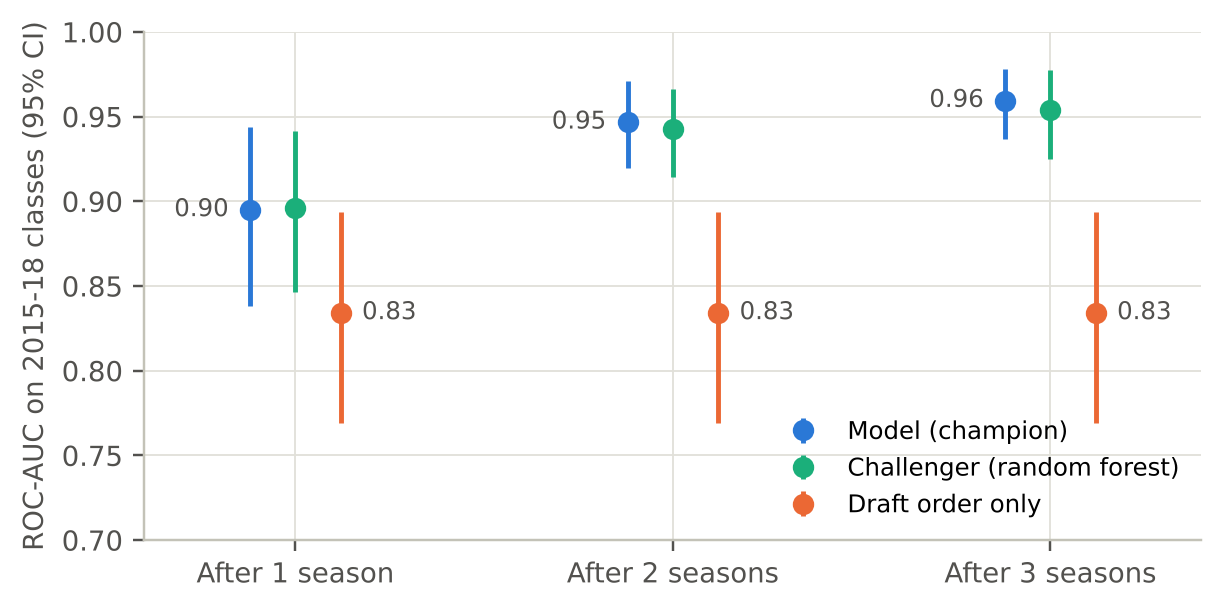

In [6]:
m = json.loads((cfg["paths"]["outputs_dir"] / "metrics.json").read_text())
bt = m["backtest"]
rows = []
for h, r in bt["horizons"].items():
    for k, name in [("champion", "Model"), ("challenger", "Challenger"), ("draft_baseline", "Draft order")]:
        a = r[k]["auc"]
        rows.append({"seasons": int(h), "approach": name, "AUC": a["est"], "95% CI": f"{a['lo']:.3f}-{a['hi']:.3f}",
                     "PR-AUC": r[k]["pr_auc"]["est"], "Brier": r[k]["brier"]["est"]})
display(pd.DataFrame(rows).pivot_table(index="approach", columns="seasons", values=["AUC", "PR-AUC", "Brier"]).round(3))
g = bt["horizons"]["3"]["champion"]["auc_gain_vs_reference"]
print(f"AUC gain over draft order after 3 seasons: +{g['est']:.3f} (95% CI {g['lo']:.3f} to {g['hi']:.3f}); positive in {g['share_of_resamples_positive']:.0%} of resamples")
display(Image("outputs/figures/fig1_auc_by_horizon.png", width=620))

Extension-decision group (still in league in year 3): n = 232 | AUC model 0.937 vs draft 0.777
Six-season survivors (comparable to Milosevic et al. 2026): AUC model 0.888 vs draft 0.713


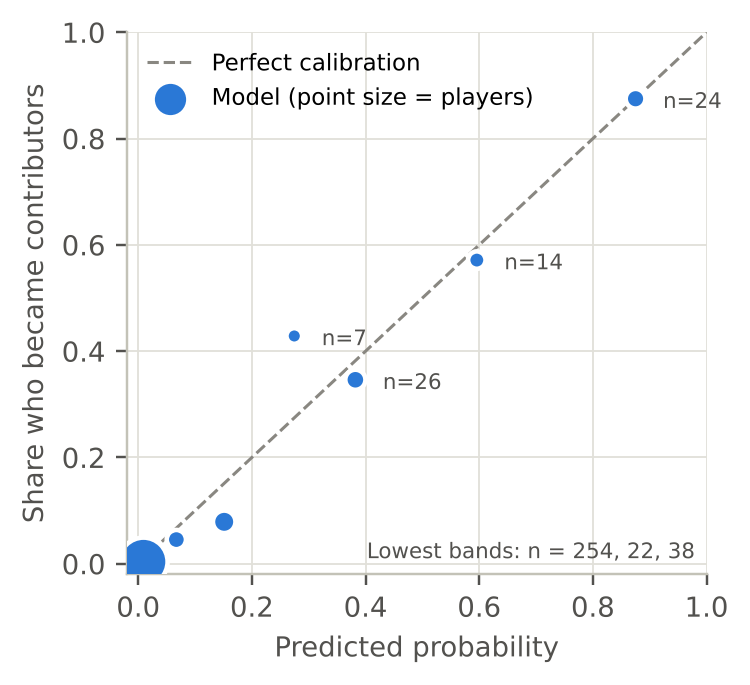

In [7]:
h3 = bt["horizons"]["3"]
print("Extension-decision group (still in league in year 3): n =", h3["extension_population"]["n"],
      "| AUC model %.3f vs draft %.3f" % (h3["extension_population"]["champion"]["auc"], h3["extension_population"]["draft"]["auc"]))
print("Six-season survivors (comparable to Milosevic et al. 2026): AUC model %.3f vs draft %.3f" % (h3["six_season_survivors"]["champion_auc"], h3["six_season_survivors"]["draft_auc"]))
display(Image("outputs/figures/fig3_calibration.png", width=360))

## 6. Business translation: shortlists, thresholds and net benefit

Because the probabilities are calibrated, the decision threshold comes straight from the cost of mistakes:
**threshold = 1 / (1 + cost ratio)**. If missing a contributor costs three times a wasted offer, the threshold is 0.25.

,threshold,flagged,caught,missed,false_flags,recall,precision,weighted_cost
cost_ratio,,,,,,,,
1:1,0.500,38,29,17,9,0.630,0.763,26
2:1,0.333,60,37,9,23,0.804,0.617,41
3:1,0.250,70,41,5,29,0.891,0.586,44
5:1,0.167,83,43,3,40,0.935,0.518,55


Top-10% shortlist contributors: model 27 vs draft 19 (of 38)
Contributors missed by a top-20% shortlist: model 4 vs draft 18 (of 46)
Net benefit per 100 players at 0.25: {'Model': 8.14, 'Draft order': 3.03, 'Flag everyone': -17.4}


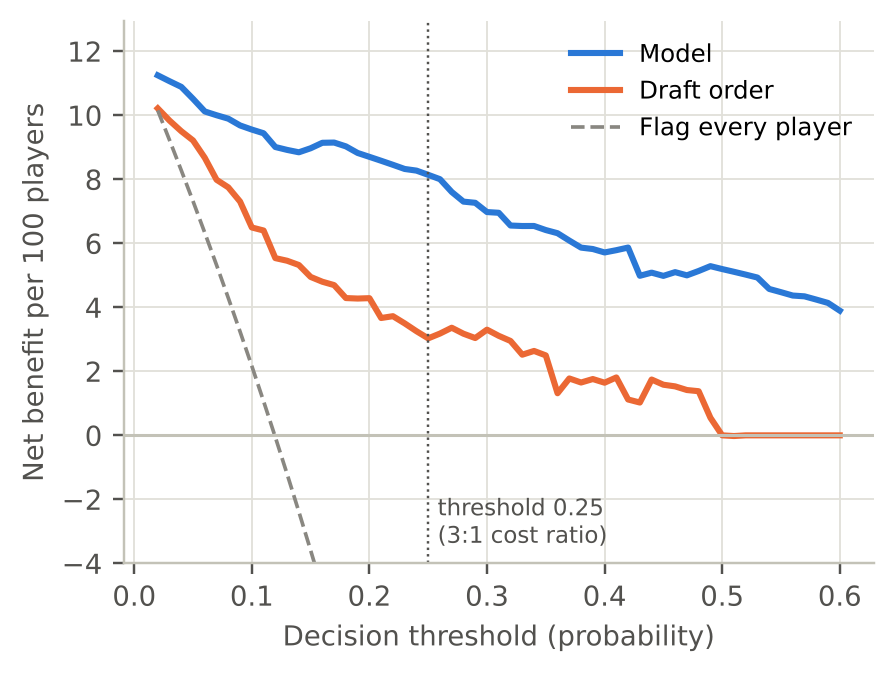

In [8]:
display(pd.DataFrame(h3["cost_thresholds"]).set_index("cost_ratio"))
s = h3["shortlists"]
a, b = s["top_10pct"], s["top_20pct"]
print(f"Top-10% shortlist contributors: model {a['model']['contributors']} vs draft {a['draft_order']['contributors']} (of {a['model']['size']})")
print(f"Contributors missed by a top-20% shortlist: model {b['model']['missed']} vs draft {b['draft_order']['missed']} (of {b['model']['total_contributors']})")
print("Net benefit per 100 players at 0.25:", bt["net_benefit_at_threshold"])
display(Image("outputs/figures/fig4_decision_curve.png", width=430))

## 7. Fairness audit

In [9]:
audit = pd.DataFrame(bt["subgroup_audit_h3"])
audit[audit.group != "Unknown"].set_index(["dimension", "group"])[["n", "contributors", "auc", "mean_pred", "observed", "calibration_gap", "miss_rate", "false_flag_rate", "judged"]]

n  contributors    auc  mean_pred  observed  calibration_gap  miss_rate  false_flag_rate  judged
dimension   group                                                                                                                    
position    Center                  70            20  0.920      0.328     0.286            0.042      0.050            0.260    True
            Forward                106             7  0.954      0.065     0.066           -0.001      0.143            0.040    True
            Guard                  157            16  0.967      0.099     0.102           -0.003      0.188            0.071    True
            Wing (G/F)              52             3  0.986      0.105     0.058            0.047      0.000            0.041   False
draft_tier  2nd round / undrafted  264            12  0.962      0.052     0.045            0.007      0.250            0.036    True
            Late 1st (15-30)        64             8  0.902      0.175     0.125            0.050      0.125            0.143    True
            Lottery (1-14)          57            26  0.918      0.452     0.456           -0.004      0.038            0.387    True
origin      International           90            15  0.956      0.180     0.167            0.013      0.067            0.093    True
            USA                    295            31  0.960      0.117     0.105            0.012      0.129            0.083    True
height_band 6'5"-6'8"              168            12  0.964      0.085     0.071            0.014      0.083            0.045    True
            6'9"-7'0"               98            19  0.939      0.229     0.194            0.035      0.053            0.165    True
            7'1"+                    9             2  1.000      0.245     0.222            0.022      0.000            0.143   False
            <=6'4"                 110            13  0.960      0.108     0.118           -0.010      0.231            0.082    True

Ranking quality is similar across groups and every judged group is within the ±0.05 calibration tolerance.
The watch-point is that **small guards and late picks are missed more often** (around 1 in 4 of their contributors at
0.25). Part of the cause is the construct, because Game Score credits rebounds and blocks. The mitigation is a
mandatory scout review for guards and late picks scoring 0.10–0.25, and a position-relative construct to test
in v1.1.

## 8. Explaining a score: Jalen Brunson in the 2021 extension window (replay)

In [10]:
replay = json.loads((cfg["paths"]["outputs_dir"] / "replay_2015_2018.json").read_text())
b = next(r for r in replay if r["name"] == "Jalen Brunson")
print(f"{b['name']} ({b['draft']}): {b['p']:.0%} (80% range {b['p_low']:.0%}-{b['p_high']:.0%}), ranked {b['class_rank']} of {b['class_size']} in his class -> {b['status']}")
print("Pushes up:  ", "; ".join(f"{d['label']} ({d['value']})" for d in b["drivers_up"]))
print("Pushes down:", "; ".join(f"{d['label']} ({d['value']})" for d in b["drivers_down"]))
display(pd.DataFrame(b["comparables"]))
print("Actual outcome:", "contributor" if b["outcome"] else "not a contributor", f"({b['high_impact_seasons']} high-impact seasons)")

Jalen Brunson (Pick 33): 42% (80% range 33%-56%), ranked 13 of 105 in his class -> Flag for review
Pushes up:   best season rank (total impact) (86th percentile); Game Score per 100 (+0.2 vs league); best season rank (per possession) (77th percentile)
Pushes down: defensive rebounds per 100 (-1.7 vs league); steals per 100 (-0.5 vs league); blocks per 100 (-0.9 vs league)


,name,debut,contributor,high_impact_seasons
0,Aaron Brooks,2007,0,0
1,Reggie Jackson,2011,1,3
2,Jeff Teague,2009,1,5
3,Leandro Barbosa,2003,1,3
4,Marcus Thornton,2009,0,0


Actual outcome: contributor (5 high-impact seasons)


## 9. Live scoring with the registered models (no retraining)

In [11]:
M, reg = pl.load_registered(cfg)
live = pd.DataFrame(pl.score_live(cfg, D, M))
print("Registry:", reg["version"], "|", reg["champion"], "| status:", reg["status"])
print(live.groupby(["debut", "status"]).size().unstack(fill_value=0))
ext = live[live.debut == D["latest_season"] - 2].sort_values("p", ascending=False)
ext[["name", "draft", "p", "p_low", "p_high", "p_challenger", "status", "minutes"]].head(10)

Registry: 1.0.0 | {'model': 'Logistic regression', 'calibration': 'sigmoid'} | status: Candidate - awaiting Model Review Board
status  Below threshold  Flag for review  Insufficient evidence
debut                                                          
2023                 40               15                      9
2024                 40               16                     25
2025                 24               17                     62


,name,draft,p,p_low,p_high,p_challenger,status,minutes
206,Victor Wembanyama,Pick 1,0.998,0.994,0.999,0.947,Flag for review,5442
192,Chet Holmgren,Pick 2,0.962,0.940,0.979,0.938,Flag for review,5231
209,Amen Thompson,Pick 4,0.870,0.815,0.933,0.829,Flag for review,6476
218,Keyonte George,Pick 16,0.829,0.737,0.884,0.826,Flag for review,5828
207,Brandon Miller,Pick 2,0.678,0.513,0.771,0.667,Flag for review,5216
235,Brandin Podziemski,Pick 19,0.548,0.495,0.658,0.481,Flag for review,5950
210,Ausar Thompson,Pick 5,0.484,0.366,0.630,0.425,Flag for review,4746
214,GG Jackson,Pick 45,0.474,0.290,0.585,0.245,Flag for review,2832
239,Tristan Vukcevic,Pick 42,0.419,0.309,0.613,0.262,Flag for review,1298
215,Cam Whitmore,Pick 20,0.392,0.210,0.518,0.268,Flag for review,2001


## 10. Monitoring: is the model still healthy?

In [12]:
pd.DataFrame(m["monitoring"]["checks"])[["status", "check", "value", "action"]]

,status,check,value,action
0,RED,Field integrity: games-started flag plausible ...,27 of 36 seasons implausible,Field excluded from the model; raise a data-qu...
1,AMBER,Data drift on the four most influential monito...,1 of 4 outside historical range,Check calibration on the newest labelled class...
2,RED,"Data drift on any monitored feature, 2025 clas...","2 red, 2 amber of 10",Investigate the feature at the next monthly re...
3,GREEN,Calibration gap on newest labelled classes (20...,0.012,Recalibrate if RED; report at Model Review Boa...
4,AMBER,"Contributor base rate, last 4 labelled classes...",-0.024,Review construct thresholds with steering if RED
5,GREEN,Champion-challenger disagreement on live watch...,0.056,Analyst reviews disagreeing players before bri...


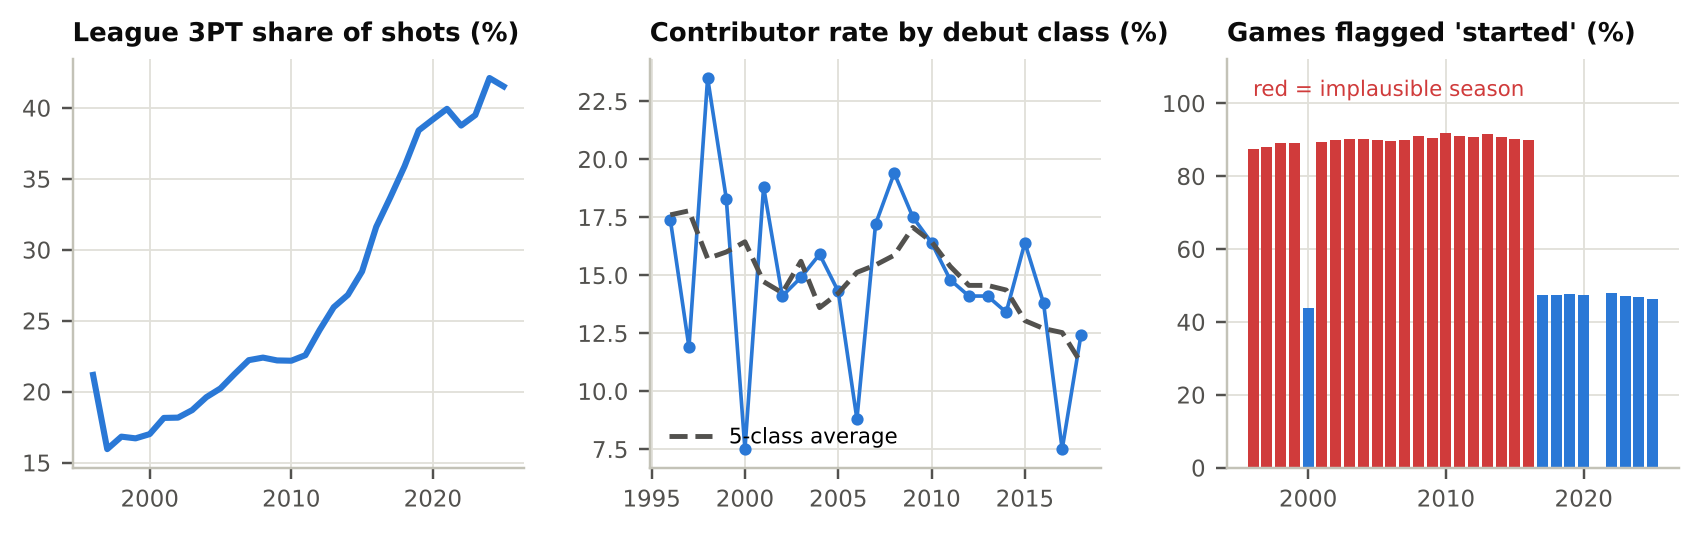

In [13]:
display(Image("outputs/figures/fig7_drift.png", width=760))

## Summary

* After three seasons the model ranks future contributors far better than draft order (AUC 0.96 against 0.83), and its
  probabilities are calibrated, so the business can set the threshold from the cost of mistakes.
* It is a transparent, maintainable champion with a challenger cross-check, per-player uncertainty, drivers and
  comparables, and an explicit "insufficient evidence" state.
* Monitoring found a real data defect (the started flag) and flags real drift (the three-point era, a falling contributor
  rate). Off-season retraining under Model Review Board approval keeps it current.
* The next evidence must come from people: the scout blind review (E3) and the shadow pilot (E4) in `docs/evaluation_protocol.md`.